# 02 · Yield prediction (XGBoost quantile regression)

**Question:** how much will this crop yield here this season — and how uncertain is that?

| | |
|---|---|
| Dataset | [Agricultural Crop Yield in Indian States — Kaggle](https://www.kaggle.com/datasets/akshatgupta7/crop-yield-in-indian-states-dataset) |
| File | `ml/data/raw/crop_yield/crop_yield.csv` |
| Rows | ~19,700 (state × crop × season × year, 1997–2020) |
| Features | crop, season, state, year, annual rainfall, fertilizer and pesticide per hectare |
| Target | yield in tonnes/hectare (= Production ÷ Area), modelled on a log scale |
| Model | **one** XGBoost model with three outputs: P10, P50, P90 |

The backend shows P50 as the expected yield and P10–P90 as the likely range, converted
to quintal/acre. No LLM is involved in any number (spec §9).

**Honest evaluation:** we train on earlier years and test on the latest years — exactly how
the model will be used. A random split would leak each state's trend into the test set.

In [1]:
import sys
from pathlib import Path

ML_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agrismart_ml.registry import ARTIFACTS_DIR, DATA_DIR

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)
print("Data folder:     ", DATA_DIR)
print("Artifacts folder:", ARTIFACTS_DIR)

Data folder:      C:\AgriSmart\ml\data\raw
Artifacts folder: C:\AgriSmart\ml\artifacts


In [2]:
from agrismart_ml import yield_model

DATA = DATA_DIR / "crop_yield" / "crop_yield.csv"
assert DATA.exists(), f"Download the dataset and place the CSV at {DATA}"
frame = yield_model.load(DATA)
frame.sample(5, random_state=0)

Loaded 10429 rows: 19 crops, 30 states, years 1997–2020


,crop,season,state,crop_year,area_ha,production_t,annual_rainfall,fertilizer_kg,pesticide_kg,fertilizer_per_ha,pesticide_per_ha,yield_t_ha
1297,mustard,rabi,West Bengal,2008,412488.0,315330.0,1560.1,5.900228e+07,37123.92,143.04,0.09,0.764459
8979,jowar,kharif,Uttar Pradesh,2019,168047.0,226638.0,814.5,2.886375e+07,62177.39,171.76,0.37,1.348658
5397,ragi,kharif,Maharashtra,2008,125500.0,125000.0,1052.8,1.795152e+07,11295.00,143.04,0.09,0.996016
2930,sugarcane,whole_year,Uttar Pradesh,1997,1985223.0,121066703.0,473.9,1.889337e+08,615419.13,95.17,0.31,60.983931
8013,maize,kharif,Bihar,2017,223242.0,535877.0,1112.0,3.514722e+07,84831.96,157.44,0.38,2.400431


Crops whose production is recorded in bales or nuts (cotton, jute, coconut) are excluded in `catalog.YIELD_CROPS`, as are aggregate classes like *Other pulses*.

In [3]:
frame.groupby("crop")["yield_t_ha"].describe()[["count", "25%", "50%", "75%"]].round(2)

,count,25%,50%,75%
crop,,,,
bajra,512.0,0.71,1.06,1.81
banana,237.0,12.86,18.38,41.33
black_gram,714.0,0.38,0.54,0.72
chickpea,480.0,0.65,0.84,1.03
green_gram,718.0,0.32,0.49,0.66
groundnut,709.0,0.93,1.21,1.74
jowar,501.0,0.72,0.97,1.29
lentil,315.0,0.53,0.71,0.83
maize,954.0,1.54,2.04,2.85


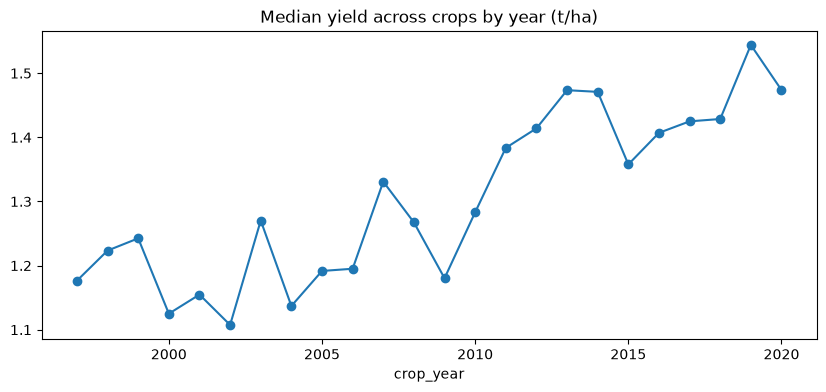

In [4]:
(frame.groupby("crop_year")["yield_t_ha"].median()).plot(marker="o", title="Median yield across crops by year (t/ha)");

## Train (temporal split, early stopping on validation years)

## Tune hyperparameters
Random search scored by the **quantile (pinball) loss on the validation years** (the two years
before the test period). The three test years are untouched until the final evaluation, so the
reported error and P10–P90 coverage stay honest forward-looking estimates.

In [5]:
TRIALS = 25  # each trial trains with early stopping (~20-60 s on CPU)
search = yield_model.tune(frame, trials=TRIALS)
best = search.iloc[0]
print(f"best validation pinball loss {best.valid_pinball:.5f} after {best.rounds} rounds")
print("best params:", best.params)
search[["valid_pinball", "rounds"]].head(10)

best validation pinball loss 0.04287 after 469 rounds
best params: {'learning_rate': 0.08, 'max_depth': 10, 'min_child_weight': 1, 'subsample': 0.7, 'colsample_bytree': 1.0, 'lambda': 0.5}


,valid_pinball,rounds
0,0.042869,469
1,0.043051,1123
2,0.043409,1774
3,0.044299,2607
4,0.044982,1812
5,0.045147,2667
6,0.045186,4000
7,0.045831,1056
8,0.045831,1056
9,0.045833,1911


In [6]:
baseline = yield_model.train(frame)                    # defaults, for comparison only
trained = yield_model.train(frame, params=best.params)  # the model we export
pd.DataFrame({"default params": baseline.metrics, "tuned params": trained.metrics})

[0]	valid-quantile:0.20840


[200]	valid-quantile:0.06368


[400]	valid-quantile:0.05346


[600]	valid-quantile:0.04974


[800]	valid-quantile:0.04817


...

[0]	valid-quantile:0.20367


[200]	valid-quantile:0.04551


[400]	valid-quantile:0.04296


[518]	valid-quantile:0.04290


,default params,tuned params
test_mae_t_ha,1.739,1.5079
test_rmse_t_ha,6.1229,5.0264
test_r2,0.8614,0.9066
test_mape_pct,15.59,14.44
p10_p90_coverage,0.7712,0.7847
p10_p90_coverage_uncalibrated,0.5829,0.5775
interval_scale,1.5,1.75
best_iteration,1538,468
train_years,1997-2015,1997-2015
test_years,2018-2020,2018-2020


`p10_p90_coverage` should be close to **0.80** — that is what makes the shown range trustworthy.

In [7]:
yield_model.per_crop_errors(trained)

,rows,median_abs_pct_error
crop,,
lentil,37,6.858974
rice,120,9.074211
pigeon_pea,53,11.386662
ragi,53,12.067513
sugarcane,53,13.247046
black_gram,82,13.318446
wheat,49,14.433343
groundnut,77,14.450719
mustard,53,15.533397


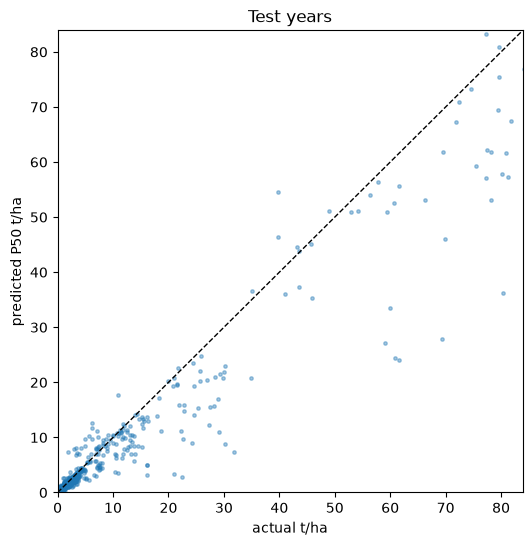

In [8]:
test = trained.test_frame
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test["yield_t_ha"], trained.test_quantiles[:, 1], s=6, alpha=0.4)
limit = np.percentile(test["yield_t_ha"], 99)
ax.plot([0, limit], [0, limit], "k--", lw=1)
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="actual t/ha", ylabel="predicted P50 t/ha", title="Test years");

## Know the limits

* Data are **district/state aggregates**, not individual farms; the estimate is "a typical
  farm like yours", not a guarantee. The app always shows the range, not just one number.
* Irrigation, variety and sowing date are not in this dataset; record actual harvests in the
  app (`crop_cycles.actual_yield_quintals`) to build a better farm-level dataset over time.
* Missing farmer inputs (rainfall, fertilizer, pesticide) are filled with training medians
  saved in `metadata.json → defaults`, and the API lists exactly which values were assumed.

## Export

In [9]:
directory = yield_model.export(trained, DATA)

Exported C:\AgriSmart\ml\artifacts\yield\yield_v3


## Put the model live

Versions are never overwritten — each export creates a new `…_vN` folder. To serve it:

* **Admin dashboard → Models →** *Register* and tick *Activate*, or
* from `backend/`: `python -m app.cli register-model yield <version> --activate`

Rolling back is the same command with the previous version (`activate-model`). Every API
instance picks up the change within a minute — no restart.